# Bank Customer Churn Prediction
### Internship Project: DevelopersHub Corporation
**Author:** Ahmad Ammar (GitHub: [@AAmmar2005](https://github.com/AAmmar2005))

**Objective:**
Build a classification model that predicts whether a bank customer will leave (churn) or stay.
The analysis uses the Churn Modelling dataset (10,000 customers) and a Logistic Regression model.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
)

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the Data

In [2]:
churn_df = pd.read_csv("Churn_Modelling.csv")

print("Data Preview:")
churn_df.head()

Data Preview:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Basic Checks

In [3]:
print("Dataset Shape:", churn_df.shape)
print("\nColumn Information:")
churn_df.info()

print("\nMissing values:", churn_df.isnull().sum().sum())
print("Duplicate rows:", churn_df.duplicated().sum())

Dataset Shape: (10000, 14)

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB

Missing values: 0
Duplicate rows: 0


### Target Distribution
Before modelling, check how balanced the target column `Exited` is (1 = customer left, 0 = customer stayed).

Share of customers (%):
Exited
Stayed (0)    79.63
Exited (1)    20.37
Name: proportion, dtype: float64


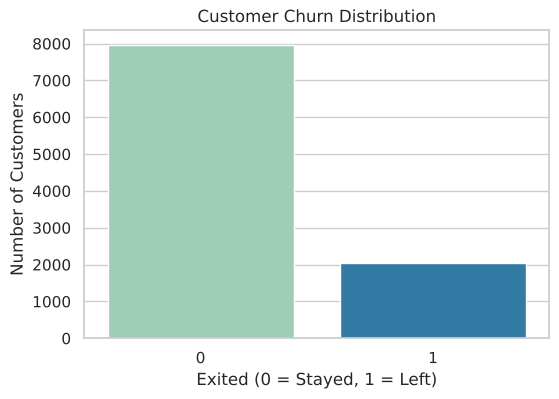

In [4]:
churn_rate = churn_df["Exited"].value_counts(normalize=True).mul(100).round(2)
print("Share of customers (%):")
print(churn_rate.rename({0: "Stayed (0)", 1: "Exited (1)"}))

plt.figure(figsize=(6, 4))
sns.countplot(x="Exited", data=churn_df, hue="Exited", palette="YlGnBu", legend=False)
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.show()

## 4. Data Cleaning
Drop identifier columns that carry no predictive information.

In [5]:
churn_df = churn_df.drop(["RowNumber", "CustomerId", "Surname"], axis=1)

print("Columns dropped. Remaining columns:", churn_df.columns.tolist())

Columns dropped. Remaining columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


## 5. Encoding
`Geography` and `Gender` are text columns. They are converted with **one-hot encoding**, not `LabelEncoder`, because label encoding would give France/Spain/Germany an artificial order (0/1/2) that the model could misinterpret.

In [6]:
churn_df = pd.get_dummies(churn_df, columns=["Geography", "Gender"], drop_first=True, dtype=int)

print("Categorical columns encoded successfully.")
print("Columns:", churn_df.columns.tolist())

Categorical columns encoded successfully.
Columns: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


## 6. Splitting and Scaling

In [7]:
# Split the data into features (X) and target (y)
X = churn_df.drop("Exited", axis=1)
y = churn_df["Exited"]

# 80% train / 20% test split (stratified to keep the same churn ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features (fit on the training data only)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Data split and scaling is done.")
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Data split and scaling is done.
Train size: 8000 | Test size: 2000


## 7. Model Training

In [8]:
# Logistic Regression with a higher max_iter so it converges
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

print("Logistic Regression model training finished.")

Logistic Regression model training finished.


## 8. Evaluation

In [9]:
y_preds = lr_model.predict(X_test)
y_proba = lr_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_preds), 4))
print("Precision:", round(precision_score(y_test, y_preds), 4))
print("Recall   :", round(recall_score(y_test, y_preds), 4))
print("F1-score :", round(f1_score(y_test, y_preds), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_preds, target_names=["Stayed", "Exited"]))

# Baseline: accuracy if the model always predicted "Stayed"
baseline = (y_test == 0).mean()
print("Baseline accuracy (always predict 'Stayed'):", round(baseline, 4))

Accuracy : 0.808


Precision: 0.5891
Recall   : 0.1867
F1-score : 0.2836
ROC-AUC  : 0.7748

Classification Report:


              precision    recall  f1-score   support

      Stayed       0.82      0.97      0.89      1593
      Exited       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000

Baseline accuracy (always predict 'Stayed'): 0.7965


### Confusion Matrix

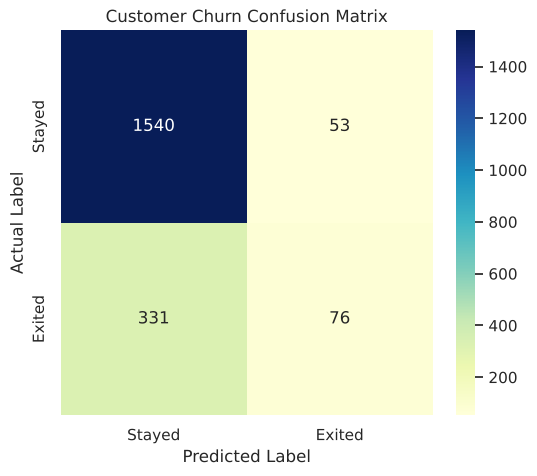

In [10]:
cm_data = confusion_matrix(y_test, y_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_data, annot=True, fmt="d", cmap="YlGnBu",
            xticklabels=["Stayed", "Exited"], yticklabels=["Stayed", "Exited"])
plt.title("Customer Churn Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### ROC Curve

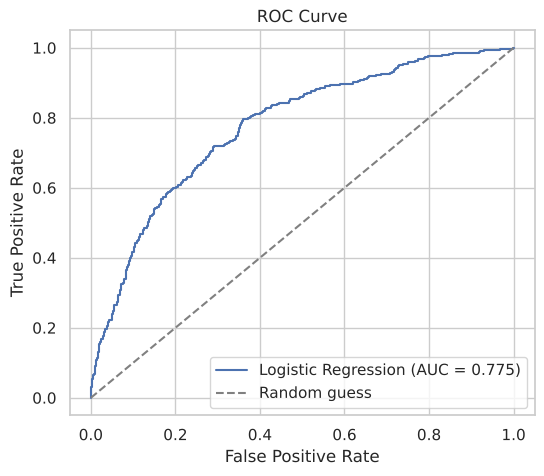

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

## 9. Feature Importance
Coefficients of the scaled features. Positive values push towards churn, negative values towards staying.

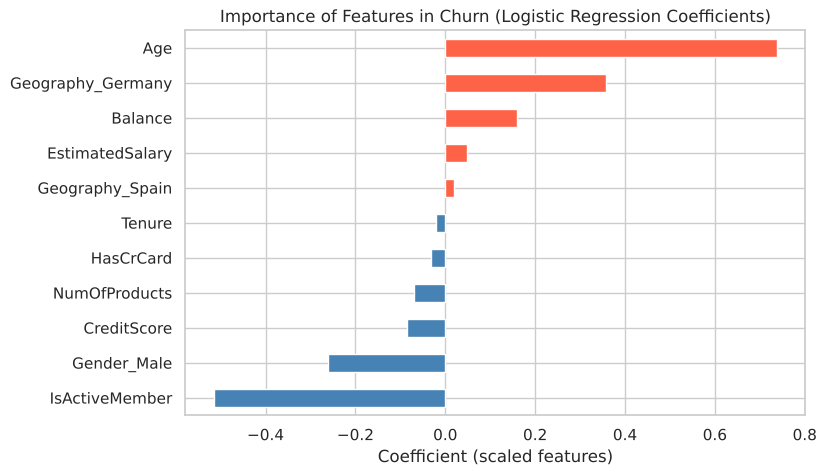

In [12]:
feature_weights = pd.Series(lr_model.coef_[0], index=X.columns).sort_values()
colors = ["tomato" if w > 0 else "steelblue" for w in feature_weights]

plt.figure(figsize=(8, 5))
feature_weights.plot(kind="barh", color=colors)
plt.title("Importance of Features in Churn (Logistic Regression Coefficients)")
plt.xlabel("Coefficient (scaled features)")
plt.show()

## Key Insights

1. The model reaches an accuracy of about **81%**, but accuracy alone is misleading here: about 80% of customers stay, so a model that always predicts "Stayed" would already score almost the same.
2. The dataset is imbalanced, so Precision, Recall, F1 and ROC-AUC matter more. The model has a ROC-AUC of about **0.77**, but a low **recall of about 19%**, meaning it catches only a small share of the customers who actually leave.
3. From the feature-importance chart, **Age** (older customers churn more), **IsActiveMember** (active members churn less) and **Geography_Germany** (higher churn than France) have the strongest influence on churn.
4. Without scaling, the model gave convergence warnings, so the features are scaled with `StandardScaler`.
5. `Geography` and `Gender` are one-hot encoded instead of label encoded, so the model does not read a false order into the countries.

### Possible Improvements
- Handle the class imbalance (for example `class_weight="balanced"` or SMOTE) to improve recall.
- Compare with other models such as Random Forest or Gradient Boosting.
- Tune the decision threshold instead of using the default 0.5.